In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from google.colab import files

In [ ]:
# upload files
uploaded=files.upload()

Saving Google_Stock_Price_Train.csv to Google_Stock_Price_Train.csv


In [ ]:
file_name = list(uploaded.keys())[0]

print(file_name)

Google_Stock_Price_Train.csv


In [ ]:
df=pd.read_csv(file_name)
df

,Date,Open,High,Low,Close,Volume
0,1/3/2012,325.25,332.83,324.97,663.59,"7,380,500"
1,1/4/2012,331.27,333.87,329.08,666.45,"5,749,400"
2,1/5/2012,329.83,330.75,326.89,657.21,"6,590,300"
3,1/6/2012,328.34,328.77,323.68,648.24,"5,405,900"
4,1/9/2012,322.04,322.29,309.46,620.76,"11,688,800"
...,...,...,...,...,...,...
1253,12/23/2016,790.90,792.74,787.28,789.91,"623,400"
1254,12/27/2016,790.68,797.86,787.66,791.55,"789,100"
1255,12/28/2016,793.70,794.23,783.20,785.05,"1,153,800"
1256,12/29/2016,783.33,785.93,778.92,782.79,"744,300"


In [ ]:
# validation
required_columns=[
    "Date","Open","High","Low","Close","Volume"
]
print("Checking Required columns....")

missing_columns=[]

for col in required_columns:
    if col not in df.columns:
      missing_columns.append(col)

if len(missing_columns) == 0:
    print("All required columns are present.")

else:
    print("Missing Columns :", missing_columns)

Checking Required columns....
All required columns are present.


In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1258 entries, 0 to 1257
Data columns (total 6 columns):
 #   Column  Non-Null Count  Dtype  
---  ------  --------------  -----  
 0   Date    1258 non-null   object 
 1   Open    1258 non-null   float64
 2   High    1258 non-null   float64
 3   Low     1258 non-null   float64
 4   Close   1258 non-null   object 
 5   Volume  1258 non-null   object 
dtypes: float64(3), object(3)
memory usage: 59.1+ KB


In [ ]:
missing_value=df.isnull().sum()
print(missing_value)

Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64


In [ ]:
duplicate=df.duplicated().sum()
print(f"Duplicate Rows: {duplicate}")

Duplicate Rows: 0


In [ ]:
df["Date"] = pd.to_datetime(df["Date"])
df["Date"]

,Date
0,2012-01-03
1,2012-01-04
2,2012-01-05
3,2012-01-06
4,2012-01-09
...,...
1253,2016-12-23
1254,2016-12-27
1255,2016-12-28
1256,2016-12-29


In [ ]:
if df["Date"].is_monotonic_increasing:

    print("Dataset is sorted by date.")

else:

    print("Dataset is NOT sorted.")

    df = df.sort_values("Date")


Dataset is sorted by date.


In [ ]:
print("\n========== VALIDATION REPORT ==========\n")

print("Rows :", df.shape[0])

print("Columns :", df.shape[1])

print("Duplicate Rows :", duplicate)

print(df.isnull().sum())

print("\nDataset Ready for Next Module ✅")


========== VALIDATION REPORT ==========

Rows : 1258
Columns : 6
Duplicate Rows : 0
Date      0
Open      0
High      0
Low       0
Close     0
Volume    0
dtype: int64

Dataset Ready for Next Module ✅


In [ ]:
# EDA
print("="*60)
print("STATISTICAL SUMMARY")
print("="*60)

display(df.describe())

STATISTICAL SUMMARY


,Date,Open,High,Low
count,1258,1258.000000,1258.000000,1258.000000
mean,2014-07-03 20:00:45.786963456,533.709833,537.880223,529.007409
min,2012-01-03 00:00:00,279.120000,281.210000,277.220000
25%,2013-04-05 18:00:00,404.115000,406.765000,401.765000
50%,2014-07-05 00:00:00,537.470000,540.750000,532.990000
75%,2015-10-01 18:00:00,654.922500,662.587500,644.800000
max,2016-12-30 00:00:00,816.680000,816.680000,805.140000
std,NaN,151.904442,153.008811,150.552807


In [ ]:
df["Date"].max()

Timestamp('2016-12-30 00:00:00')

In [ ]:
df["Date"].max()

Timestamp('2016-12-30 00:00:00')

In [ ]:
ranges=df["Date"].max()-df["Date"].min()
print(ranges)

1823 days 00:00:00


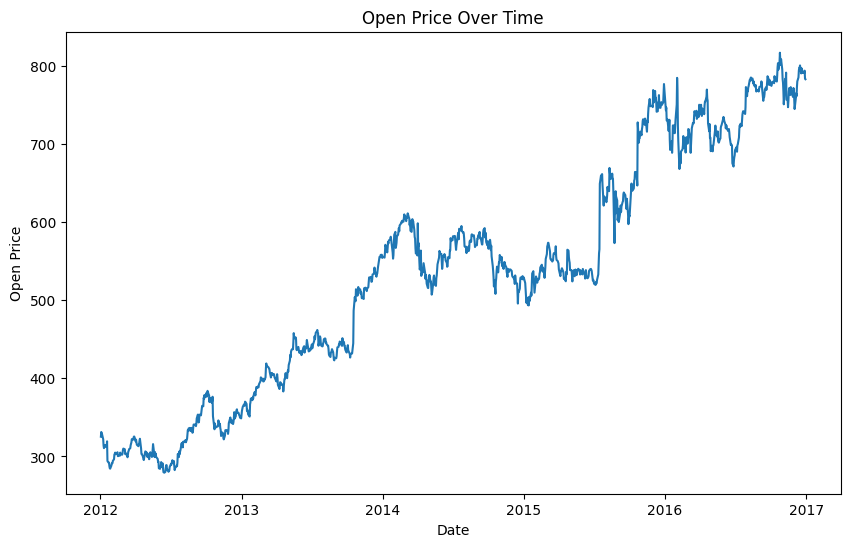

In [ ]:
plt.figure(figsize=(10,6))
plt.plot(df["Date"],df["Open"])
plt.xlabel("Date")
plt.ylabel("Open Price")
plt.title("Open Price Over Time")
plt.show()

In [ ]:
df.head()

,Date,Open,High,Low,Close,Volume
0,2012-01-03,325.25,332.83,324.97,663.59,"7,380,500"
1,2012-01-04,331.27,333.87,329.08,666.45,"5,749,400"
2,2012-01-05,329.83,330.75,326.89,657.21,"6,590,300"
3,2012-01-06,328.34,328.77,323.68,648.24,"5,405,900"
4,2012-01-09,322.04,322.29,309.46,620.76,"11,688,800"


In [ ]:
# Data Preprocessing
# We will do multivariate analysis
# ==============================
# PROJECT CONFIGURATION
# ==============================

FEATURE_COLUMNS = [
    "Open",
    "High",
    "Low",
    "Close",
    "Volume",
    "MA10",
    "MA20"
]
TARGET_COLUMN = "Open"

WINDOW_SIZE = 120

TRAIN_SPLIT = 0.80

EPOCHS = 100

BATCH_SIZE = 32

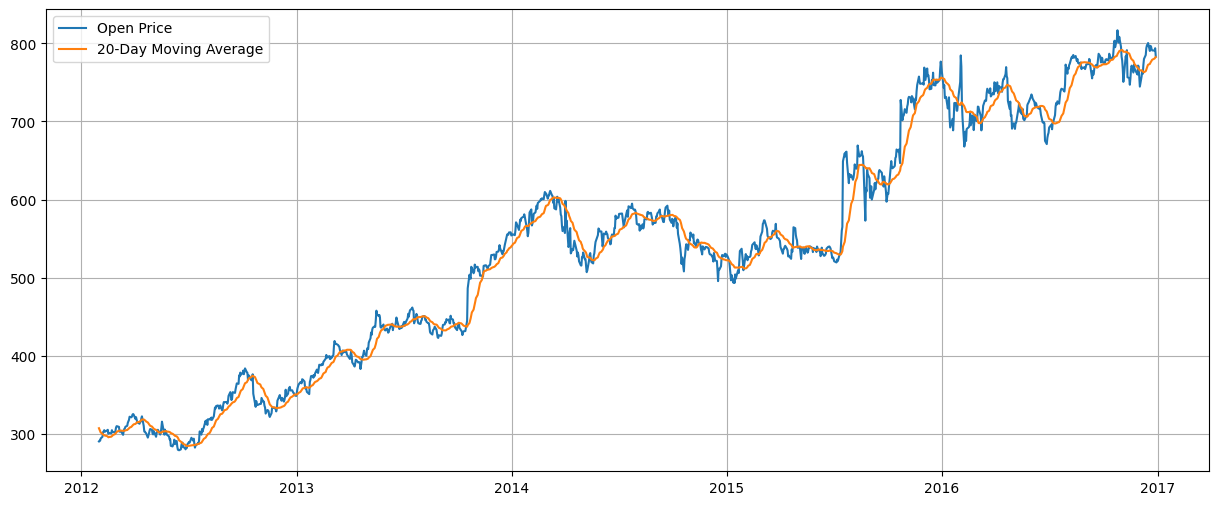

In [ ]:
df["MA20"] = df["Open"].rolling(window=20).mean()
df["MA10"] = df["Open"].rolling(window=10).mean()
df["Target"] = df[TARGET_COLUMN].shift(-1)
df = df.dropna().reset_index(drop=True)
plt.figure(figsize=(15,6))

plt.plot(df["Date"], df["Open"], label="Open Price")

plt.plot(df["Date"], df["MA20"], label="20-Day Moving Average")

plt.legend()

plt.grid(True)

plt.show()

In [ ]:
df["Close"]=df["Close"].replace(",","")

In [ ]:
df["Close"] = df["Close"].str.replace(",", "", regex=False)

In [ ]:
df["Volume"] = df["Volume"].str.replace(",", "", regex=False)

In [ ]:
df["Volume"]=df["Volume"].astype(float)

In [ ]:
df["Volume"]

,Volume
0,4300700.0
1,4658700.0
2,4847400.0
3,6360700.0
4,7386700.0
...,...
1233,972200.0
1234,623400.0
1235,789100.0
1236,1153800.0


In [ ]:
df["Close"]=df["Close"].astype(float)

In [ ]:
df["Target"]

,Target
0,291.38
1,291.34
2,294.23
3,296.39
4,302.44
...,...
1233,790.90
1234,790.68
1235,793.70
1236,783.33


In [ ]:
x=df[FEATURE_COLUMNS].values
y=df["Target"].values.reshape(-1,1)

In [ ]:
from sklearn.preprocessing import MinMaxScaler
scaler=MinMaxScaler()
x_scaled=scaler.fit_transform(x)

In [ ]:
target_scaler=MinMaxScaler()
y_scaled=target_scaler.fit_transform(y)

In [ ]:
# train test split
train_size=int(len(x_scaled)*TRAIN_SPLIT)
x_train_data = x_scaled[:train_size]
x_test_data=x_scaled[train_size-WINDOW_SIZE:]
y_train_data = y_scaled[:train_size]
y_test_data = y_scaled[train_size-WINDOW_SIZE:]

In [ ]:
def create_sequences(features,target,window_size):
  x_seq=[]
  y_seq=[]

  for i in range(window_size,len(features)):
    x_seq.append(features[i-window_size:i])
    y_seq.append(target[i])
  return np.array(x_seq), np.array(y_seq)

In [ ]:
x_train,y_train=create_sequences(
x_train_data,
y_train_data,
WINDOW_SIZE
)

In [ ]:
X_test,y_test=create_sequences(
x_test_data,
y_test_data,
WINDOW_SIZE
)

In [ ]:
print(x_train.shape)
print(y_train.shape)

(870, 120, 7)
(870, 1)


In [ ]:
# Lstm model
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Dropout,Dense,LSTM

model=Sequential()

model.add(
    LSTM(
        units=128,
        return_sequences=True,
        input_shape=(WINDOW_SIZE,len(FEATURE_COLUMNS))
    )
)
model.add(Dropout(0.2))

model.add(
    LSTM(
        units=128,
        return_sequences=True
    )
)

model.add(Dropout(0.2))

model.add(
    LSTM(
        units=32,
    )
)
model.add(Dropout(0.2))

model.add(Dense(1))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/rnn/rnn.py:199: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ lstm (LSTM)                     │ (None, 120, 128)       │        69,632 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 120, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_1 (LSTM)                   │ (None, 120, 128)       │       131,584 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 120, 128)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm_2 (LSTM)                   │ (None, 32)             │        20,608 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 32)             │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 1)              │            33 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 221,857 (866.63 KB)

 Trainable params: 221,857 (866.63 KB)

 Non-trainable params: 0 (0.00 B)

In [ ]:
model.compile(
    optimizer="adam",
    loss="mse",
    metrics=["mae"]
)

In [ ]:
print("NaN in X_train :", np.isnan(x_train).sum())
print("NaN in y_train :", np.isnan(y_train).sum())

print("NaN in X_test :", np.isnan(X_test).sum())
print("NaN in y_test :", np.isnan(y_test).sum())

NaN in X_train : 0
NaN in y_train : 0
NaN in X_test : 0
NaN in y_test : 0


In [ ]:
history=model.fit(
    x_train,
    y_train,
    epochs=EPOCHS,
    batch_size=BATCH_SIZE,
    validation_split=0.25,
    verbose=1
)

Epoch 1/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 7s 51ms/step - loss: 0.0247 - mae: 0.1132 - val_loss: 0.0205 - val_mae: 0.1211
Epoch 2/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0042 - mae: 0.0490 - val_loss: 0.0124 - val_mae: 0.0873
Epoch 3/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0035 - mae: 0.0456 - val_loss: 0.0051 - val_mae: 0.0555
Epoch 4/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 23ms/step - loss: 0.0032 - mae: 0.0436 - val_loss: 0.0067 - val_mae: 0.0607
Epoch 5/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0028 - mae: 0.0403 - val_loss: 0.0075 - val_mae: 0.0637
Epoch 6/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0028 - mae: 0.0397 - val_loss: 0.0052 - val_mae: 0.0551
Epoch 7/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 1s 23ms/step - loss: 0.0034 - mae: 0.0442 - val_loss: 0.0082 - val_mae: 0.0670
Epoch 8/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - loss: 0.0030 - mae: 0.0412 - val_loss: 0.0063 - val_mae: 0.0593
Epoch 9/100
21/21 ━━━━━━━━━━━━━━━━━━━━ 0s 22ms/step - lo

In [ ]:
# Predicting using the model
from sklearn.metrics import (
    mean_absolute_error,
    mean_squared_error,
    mean_absolute_percentage_error
)
pred=model.predict(X_test)

8/8 ━━━━━━━━━━━━━━━━━━━━ 0s 37ms/step


In [ ]:
pred=target_scaler.inverse_transform(pred)
actual_prices=target_scaler.inverse_transform(y_test)

In [ ]:
mae=mean_absolute_error(actual_prices,pred)
rmse=np.sqrt(mean_squared_error(actual_prices,pred))
mape=mean_absolute_percentage_error(actual_prices,pred)

In [ ]:
print("="*50)

print(f"RMSE : {rmse:.2f}")

print(f"MAE  : {mae:.2f}")

print(f"MAPE : {mape*100:.2f}%")

print("="*50)

RMSE : 36.93
MAE  : 33.64
MAPE : 4.47%


In [ ]:
pred=pd.DataFrame(pred)

actual_prices=pd.DataFrame(actual_prices)
actual_prices=actual_prices.iloc[10:]
print(pred.shape)
print(actual_prices.shape)

(248, 1)
(238, 1)


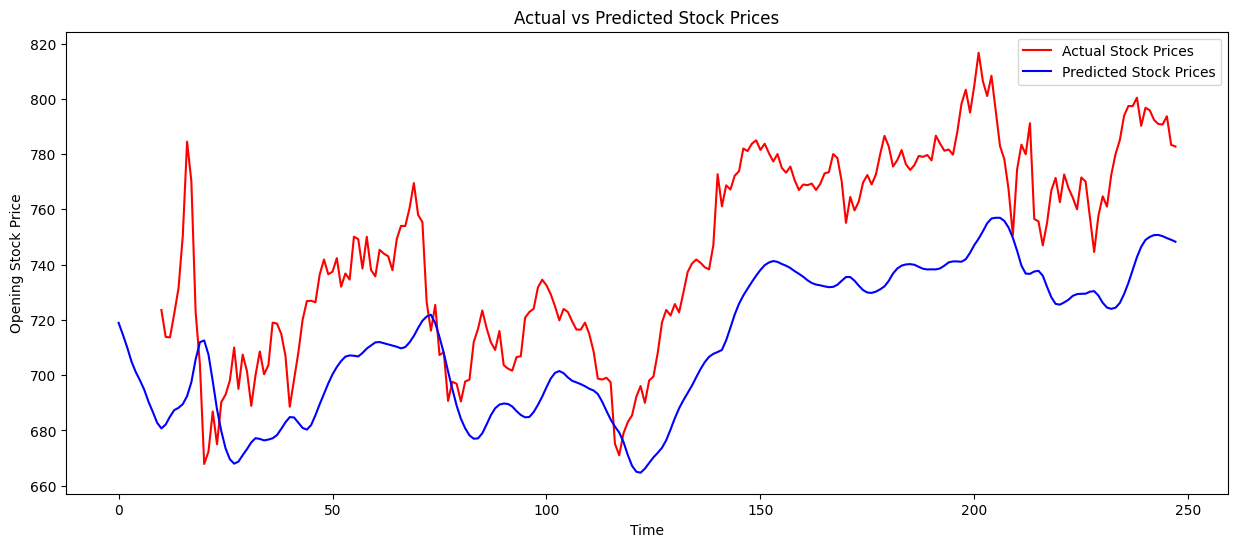

In [ ]:
plt.figure(figsize=(15,6))
plt.plot(actual_prices,
         color="red",
         label="Actual Stock Prices")

plt.plot(
    pred,
    color="blue",
    label="Predicted Stock Prices"
)

plt.title("Actual vs Predicted Stock Prices")

plt.xlabel("Time")

plt.ylabel("Opening Stock Price")

plt.legend()

plt.show()
#

In [ ]:
pred=pred.dropna().reset_index(drop=True)

In [ ]:
print(df.shape)

df.head()

(1238, 9)


,Date,Open,High,Low,Close,Volume,MA20,MA10,Target
0,2012-01-31,290.41,290.91,286.50,578.52,4300700.0,307.3540,294.486,291.38
1,2012-02-01,291.38,291.66,288.49,579.24,4658700.0,305.6605,292.410,291.34
2,2012-02-02,291.34,292.11,289.95,583.51,4847400.0,303.6640,289.614,294.23
3,2012-02-03,294.23,297.42,292.93,594.70,6360700.0,301.8840,289.621,296.39
4,2012-02-06,296.39,304.27,295.90,607.42,7386700.0,300.2865,290.069,302.44


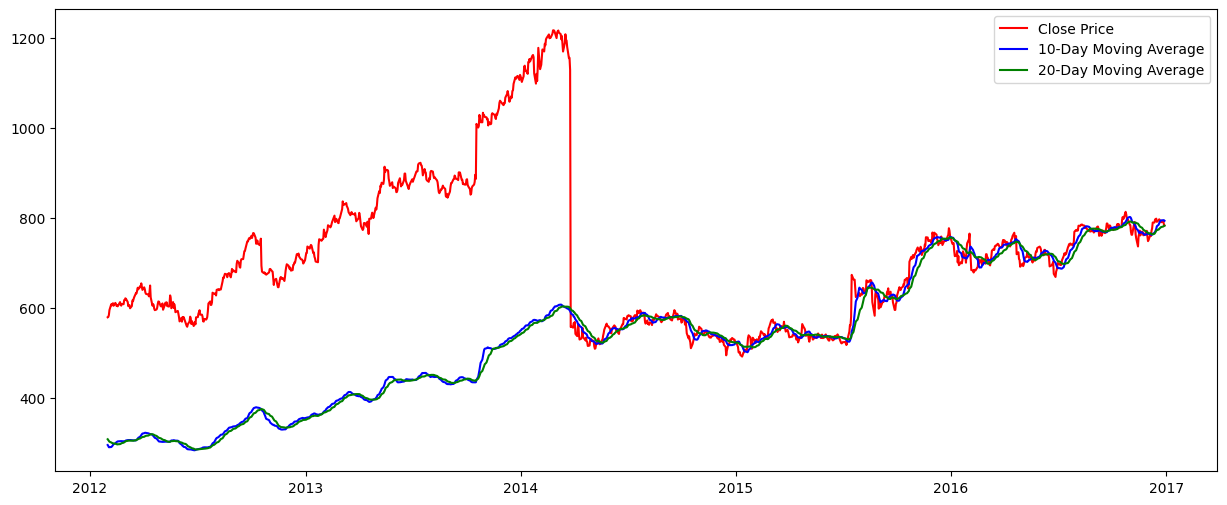

In [ ]:
plt.figure(figsize=(15,6))

plt.plot(df["Date"], df["Close"],color="red", label="Close Price")

plt.plot(df["Date"], df["MA10"],color="blue", label="10-Day Moving Average")

plt.plot(df["Date"], df["MA20"], color="green",label="20-Day Moving Average")

plt.legend()

In [ ]:
model.save("stock_prediction_model.keras")

In [ ]:
from tensorflow.keras.models import load_model

model = load_model("stock_prediction_model.keras")

In [ ]:
# saving scalar using joblib
import joblib

joblib.dump(
    scaler,
    "feature_scaler.pkl"
)

print("Feature Scaler Saved")

Feature Scaler Saved


In [ ]:
# ----------------------------------------------------------
# Save Target Scaler
# ----------------------------------------------------------

joblib.dump(
    target_scaler,
    "target_scaler.pkl"
)

print("Target Scaler Saved")

Target Scaler Saved


In [ ]:
import json

config = {

    "window_size": WINDOW_SIZE,

    "feature_columns": FEATURE_COLUMNS,

    "target_column": TARGET_COLUMN,

    "train_split": TRAIN_SPLIT

}

with open("config.json", "w") as file:

    json.dump(config, file, indent=4)

print("Configuration Saved")

Configuration Saved


In [ ]:
from tensorflow.keras.models import load_model

model = load_model("stock_prediction_model.keras")

print("Model Loaded Successfully")

Model Loaded Successfully


In [ ]:
feature_scaler = joblib.load(
    "feature_scaler.pkl"
)

In [ ]:
target_scaler = joblib.load(
    "target_scaler.pkl"
)

In [ ]:
with open("config.json", "r") as file:

    config = json.load(file)

WINDOW_SIZE = config["window_size"]

FEATURE_COLUMNS = config["feature_columns"]

TARGET_COLUMN = config["target_column"]

TRAIN_SPLIT = config["train_split"]